In [34]:
import numpy as np
import pandas as pd

In [46]:
# Install dependencies as needed:
# pip install kagglehub[pandas-datasets]
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Set the path to the file you'd like to load
file_path = "credit_card_fraud_10k.csv"

# Load the latest version
df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "miadul/credit-card-fraud-detection-dataset",
  file_path,
  # Provide any additional arguments like 
  # sql_query or pandas_kwargs. See the 
  # documenation for more information:
  # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas
)

print("First 5 records:", df.head())

/tmp/ipykernel_1290/3029191435.py:10: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


Using Colab cache for faster access to the 'credit-card-fraud-detection-dataset' dataset.
First 5 records:    transaction_id  amount  transaction_hour merchant_category  \
0               1   84.47                22       Electronics   
1               2  541.82                 3            Travel   
2               3  237.01                17           Grocery   
3               4  164.33                 4           Grocery   
4               5   30.53                15              Food   

   foreign_transaction  location_mismatch  device_trust_score  \
0                    0                  0                  66   
1                    1                  0                  87   
2                    0                  0                  49   
3                    0                  1                  72   
4                    0                  0                  79   

   velocity_last_24h  cardholder_age  is_fraud  
0                  3              40         0  
1            

In [47]:
df.head()

,transaction_id,amount,transaction_hour,merchant_category,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud
0,1,84.47,22,Electronics,0,0,66,3,40,0
1,2,541.82,3,Travel,1,0,87,1,64,0
2,3,237.01,17,Grocery,0,0,49,1,61,0
3,4,164.33,4,Grocery,0,1,72,3,34,0
4,5,30.53,15,Food,0,0,79,0,44,0


In [48]:
df.describe()

,transaction_id,amount,transaction_hour,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,175.949849,11.593300,0.097800,0.085700,61.798900,2.008900,43.468700,0.015100
std,2886.89568,175.392827,6.922708,0.297059,0.279935,21.487053,1.432559,14.979147,0.121957
min,1.00000,0.000000,0.000000,0.000000,0.000000,25.000000,0.000000,18.000000,0.000000
25%,2500.75000,50.905000,6.000000,0.000000,0.000000,43.000000,1.000000,30.000000,0.000000
50%,5000.50000,122.095000,12.000000,0.000000,0.000000,62.000000,2.000000,44.000000,0.000000
75%,7500.25000,242.480000,18.000000,0.000000,0.000000,80.000000,3.000000,56.000000,0.000000
max,10000.00000,1471.040000,23.000000,1.000000,1.000000,99.000000,9.000000,69.000000,1.000000


In [49]:
df.isnull().sum()

,0
transaction_id,0
amount,0
transaction_hour,0
merchant_category,0
foreign_transaction,0
location_mismatch,0
device_trust_score,0
velocity_last_24h,0
cardholder_age,0
is_fraud,0


In [50]:
df.duplicated().sum()

np.int64(0)

In [51]:
df['merchant_category'].unique()

array(['Electronics', 'Travel', 'Grocery', 'Food', 'Clothing'],
      dtype=object)

In [ ]:
from sklearn.preprocessing import OneHotEncoder



encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
merchant_encoded = encoder.fit_transform(
    df[['merchant_category']]
)
merchant_df = pd.DataFrame(
    merchant_encoded,
    columns=encoder.get_feature_names_out(['merchant_category']),
    index=df.index,
)
df = pd.concat([df.drop(columns='merchant_category'), merchant_df], axis=1)
df.head()

,transaction_id,amount,transaction_hour,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud,merchant_category_Clothing,merchant_category_Electronics,merchant_category_Food,merchant_category_Grocery,merchant_category_Travel
0,1,84.47,22,0,0,66,3,40,0,0.0,1.0,0.0,0.0,0.0
1,2,541.82,3,1,0,87,1,64,0,0.0,0.0,0.0,0.0,1.0
2,3,237.01,17,0,0,49,1,61,0,0.0,0.0,0.0,1.0,0.0
3,4,164.33,4,0,1,72,3,34,0,0.0,0.0,0.0,1.0,0.0
4,5,30.53,15,0,0,79,0,44,0,0.0,0.0,1.0,0.0,0.0


In [55]:
df = df.drop('transaction_id', axis = 1)

In [60]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   amount                         10000 non-null  float64
 1   transaction_hour               10000 non-null  int64  
 2   foreign_transaction            10000 non-null  int64  
 3   location_mismatch              10000 non-null  int64  
 4   device_trust_score             10000 non-null  int64  
 5   velocity_last_24h              10000 non-null  int64  
 6   cardholder_age                 10000 non-null  int64  
 7   is_fraud                       10000 non-null  int64  
 8   merchant_category_Clothing     10000 non-null  float64
 9   merchant_category_Electronics  10000 non-null  float64
 10  merchant_category_Food         10000 non-null  float64
 11  merchant_category_Grocery      10000 non-null  float64
 12  merchant_category_Travel       10000 non-null  

<Axes: xlabel='is_fraud', ylabel='count'>

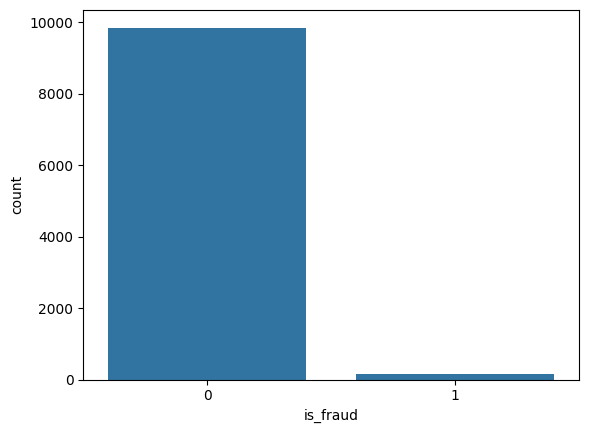

In [61]:
sns.countplot(x='is_fraud',data=df)

In [67]:
class_weights = {0: weights[0], 1: weights[1]}

In [70]:
df["is_night"] = ((df["transaction_hour"] >= 20) | (df["transaction_hour"] < 6)).astype(int)

df["hour_sin"] = np.sin(2 * np.pi * df["transaction_hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["transaction_hour"] / 24)

In [71]:
x = df.drop(['is_fraud','transaction_hour'], axis = 1)
y = df['is_fraud']

In [72]:
x

,amount,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,merchant_category_Clothing,merchant_category_Electronics,merchant_category_Food,merchant_category_Grocery,merchant_category_Travel,is_night,hour_sin,hour_cos
0,84.47,0,0,66,3,40,0.0,1.0,0.0,0.0,0.0,1,-0.500000,0.866025
1,541.82,1,0,87,1,64,0.0,0.0,0.0,0.0,1.0,1,0.707107,0.707107
2,237.01,0,0,49,1,61,0.0,0.0,0.0,1.0,0.0,0,-0.965926,-0.258819
3,164.33,0,1,72,3,34,0.0,0.0,0.0,1.0,0.0,1,0.866025,0.500000
4,30.53,0,0,79,0,44,0.0,0.0,1.0,0.0,0.0,0,-0.707107,-0.707107
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,350.91,0,0,99,4,37,0.0,0.0,1.0,0.0,0.0,1,-0.500000,0.866025
9996,410.04,0,0,70,3,25,1.0,0.0,0.0,0.0,0.0,1,0.965926,0.258819
9997,527.75,0,0,44,2,45,0.0,1.0,0.0,0.0,0.0,1,-0.707107,0.707107
9998,91.20,0,0,38,0,37,0.0,1.0,0.0,0.0,0.0,1,0.500000,0.866025


In [75]:
from sklearn.preprocessing import StandardScaler
ss = StandardScaler()
x = ss.fit_transform(x)

In [76]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x, y, test_size = 0.2, random_state= 42)

In [78]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1]),
    y=y_train
)

print(weights)


[ 0.50761421 33.33333333]


<Axes: >

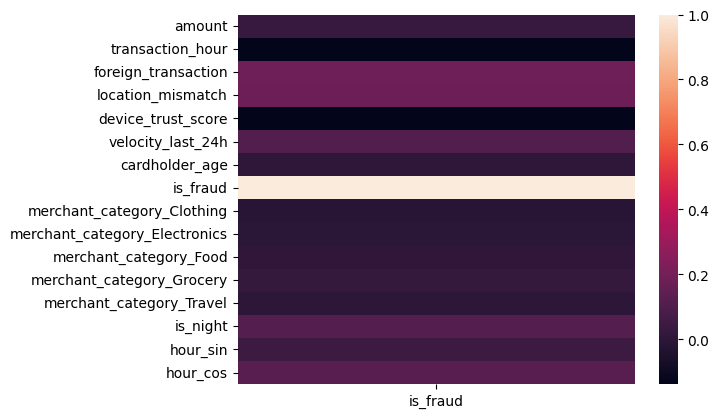

In [80]:
sns.heatmap(df.corr()[['is_fraud']])

In [83]:
import tensorflow
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense as dense, Dropout as dropout,BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping

In [87]:
model = Sequential([
    dense(126,activation='relu',input_shape=(14,)),
    BatchNormalization(),
    dropout(0.1),
    dense(64,activation='relu'),
    BatchNormalization(),
    dropout(0.1),
    dense(32,activation='relu'),
    BatchNormalization(),
    dropout(0.1),
    dense(1,activation='sigmoid')
])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [88]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 126)            │         1,890 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 126)            │           504 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 126)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         8,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,019 (50.86 KB)

 Trainable params: 12,575 (49.12 KB)

 Non-trainable params: 444 (1.73 KB)

In [89]:
callback = EarlyStopping(
    monitor="val_loss",
    min_delta=0.00001,
    patience=20,
    verbose=1,
    mode="auto",
    baseline=None,
    restore_best_weights=False
)

In [91]:
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])

In [92]:
history = model.fit(x_train, y_train,epochs = 500,validation_data=(x_test,y_test),callbacks = callback)

Epoch 1/500
250/250 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.8299 - loss: 0.4288 - val_accuracy: 0.9855 - val_loss: 0.1596
Epoch 2/500
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9826 - loss: 0.1013 - val_accuracy: 0.9875 - val_loss: 0.0535
Epoch 3/500
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9854 - loss: 0.0560 - val_accuracy: 0.9880 - val_loss: 0.0386
Epoch 4/500
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9869 - loss: 0.0418 - val_accuracy: 0.9875 - val_loss: 0.0338
Epoch 5/500
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9887 - loss: 0.0360 - val_accuracy: 0.9885 - val_loss: 0.0318
Epoch 6/500
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9887 - loss: 0.0312 - val_accuracy: 0.9885 - val_loss: 0.0270
Epoch 7/500
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9877 - loss: 0.0326 - val_accuracy: 0.9885 - val_loss: 0.0277
Epoch 8/500
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9900 - loss: 0.0287 - val_accu

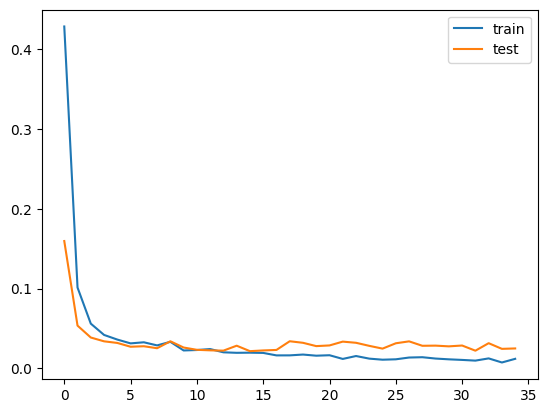

In [ ]:
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='test')
plt.legend()
plt.show()

Epoch 1/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9635 - loss: 0.1513 - val_accuracy: 0.9630 - val_loss: 0.1308
Epoch 2/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9705 - loss: 0.0621 - val_accuracy: 0.9720 - val_loss: 0.0796
Epoch 3/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9795 - loss: 0.0493 - val_accuracy: 0.9645 - val_loss: 0.1468
Epoch 4/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9688 - loss: 0.0954 - val_accuracy: 0.9735 - val_loss: 0.0809
Epoch 5/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9758 - loss: 0.0558 - val_accuracy: 0.9790 - val_loss: 0.0617
Epoch 6/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9811 - loss: 0.0564 - val_accuracy: 0.9745 - val_loss: 0.0845
Epoch 7/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9751 - loss: 0.0510 - val_accuracy: 0.9830 - val_loss: 0.0511
Epoch 8/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9808 - loss: 0.0398 - val_accuracy: 0.

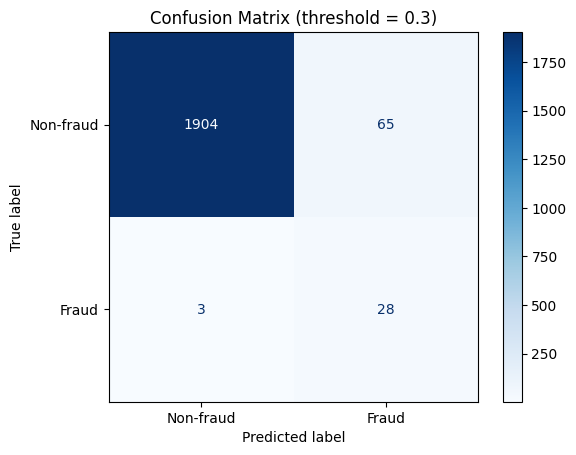

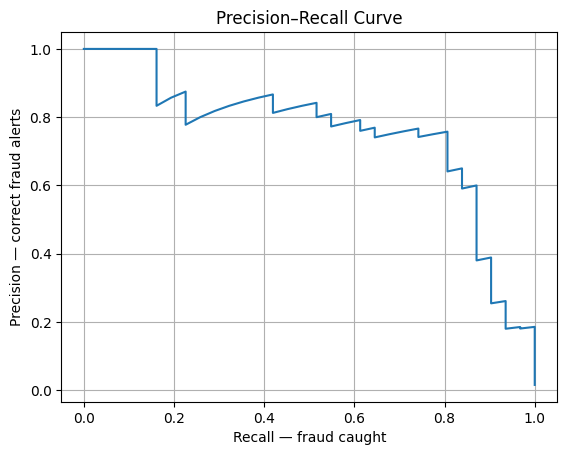

In [104]:
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    average_precision_score,
    precision_recall_curve
)
import matplotlib.pyplot as plt

# Stop when validation loss no longer improves
early_stop = EarlyStopping(
    monitor="accuracy",
    patience=3,
    restore_best_weights=True
)

# Train
history = model.fit(
    x_train,
    y_train,
    validation_data=(x_test, y_test),
    epochs=50,
    batch_size=32,
    class_weight=class_weights,
    callbacks=[early_stop],
    verbose=1
)

# Fraud probabilities on unseen test data
y_prob = model.predict(x_test).ravel()

# Choose threshold; 0.5 is only a starting point
threshold = 0.30
y_pred = (y_prob >= threshold).astype(int)

# Precision, recall, F1 for fraud/non-fraud
print(classification_report(y_test, y_pred, target_names=["Non-fraud", "Fraud"]))

# PR-AUC: more useful than accuracy for imbalanced fraud data
print("PR-AUC:", average_precision_score(y_test, y_prob))

# Confusion matrix
ConfusionMatrixDisplay(
    confusion_matrix(y_test, y_pred),
    display_labels=["Non-fraud", "Fraud"]
).plot(cmap="Blues")

plt.title(f"Confusion Matrix (threshold = {threshold})")
plt.show()

# Precision–recall curve
precision, recall, thresholds = precision_recall_curve(y_test, y_prob)

plt.plot(recall, precision)
plt.xlabel("Recall — fraud caught")
plt.ylabel("Precision — correct fraud alerts")
plt.title("Precision–Recall Curve")
plt.grid()
plt.show()